# Week 1 — Titanic Survival Prediction: Data Cleaning Project

**Dataset:** [Titanic Dataset on Kaggle (`yasserh/titanic-dataset`)](https://www.kaggle.com/datasets/yasserh/titanic-dataset)

This notebook completes all Week 1 assignments and Mini Project 1 tasks cleanly and reproducibly:
1. Load the dataset with Pandas and summarize statistics (`.info()`, `.describe()`).
2. Clean missing data using median & mode imputation (plus binary `HasCabin` feature).
3. Encode `Sex` with `LabelEncoder` and `Embarked` with `OneHotEncoder`.
4. Visualize the `Age` distribution and survival insights with Matplotlib & Seaborn.
5. Export the cleaned dataset to `outputs/titanic_cleaned.csv` and evaluate baseline survival models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from pathlib import Path

from titanic_cleaning import (
    load_dataset,
    summarize_dataset,
    clean_and_encode,
    plot_age_distribution,
    plot_eda_summary,
    evaluate_survival_models,
    CLEANED_CSV_PATH,
)

%matplotlib inline
sns.set_theme(style="whitegrid")

## Assignment 1: Load Dataset & Summarize Basic Statistics (`.info()`, `.describe()`)

In [2]:
df_raw = load_dataset()
print(f"Shape: {df_raw.shape}")
display(df_raw.head())

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
display(df_raw.describe(include="all").round(2))
stats = summarize_dataset(df_raw)
print("\nMissing Values Summary:")
display(stats["missing_summary"])

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.00,891.00,891.00,891,891,714.00,891.00,891.00,891,891.00,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.00,0.38,2.31,NaN,NaN,29.70,0.52,0.38,NaN,32.20,NaN,NaN
std,257.35,0.49,0.84,NaN,NaN,14.53,1.10,0.81,NaN,49.69,NaN,NaN
min,1.00,0.00,1.00,NaN,NaN,0.42,0.00,0.00,NaN,0.00,NaN,NaN
25%,223.50,0.00,2.00,NaN,NaN,20.12,0.00,0.00,NaN,7.91,NaN,NaN
50%,446.00,0.00,3.00,NaN,NaN,28.00,0.00,0.00,NaN,14.45,NaN,NaN
75%,668.50,1.00,3.00,NaN,NaN,38.00,1.00,0.00,NaN,31.00,NaN,NaN



Missing Values Summary:


,missing_count,missing_pct
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


## Assignments 2 & 3: Handle Missing Data & Encode `Sex` (`LabelEncoder`) and `Embarked` (`OneHotEncoder`)

In [5]:
df_clean, meta = clean_and_encode(df_raw)
print("Cleaning & Encoding Metadata:")
for k, v in meta.items():
    print(f"  {k}: {v}")

print("\nNull values remaining:", df_clean.isnull().sum().sum())
display(df_clean.head())

Cleaning & Encoding Metadata:
  age_mean_before: 29.7
  age_median_before: 28.0
  age_imputed_count: 177
  embarked_mode: S
  embarked_imputed_count: 2
  sex_mapping: {'female': 0, 'male': 1}
  embarked_columns: ['Embarked_C', 'Embarked_Q', 'Embarked_S']
  remaining_nulls: 0

Null values remaining: 0


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,1,22.0,1,0,7.2500,0,0,0,1
1,2,1,1,0,38.0,1,0,71.2833,1,1,0,0
2,3,1,3,0,26.0,0,0,7.9250,0,0,0,1
3,4,1,1,0,35.0,1,0,53.1000,1,0,0,1
4,5,0,3,1,35.0,0,0,8.0500,0,0,0,1


## Task 3: Visualize Age Distribution & EDA Summary (Matplotlib / Seaborn)

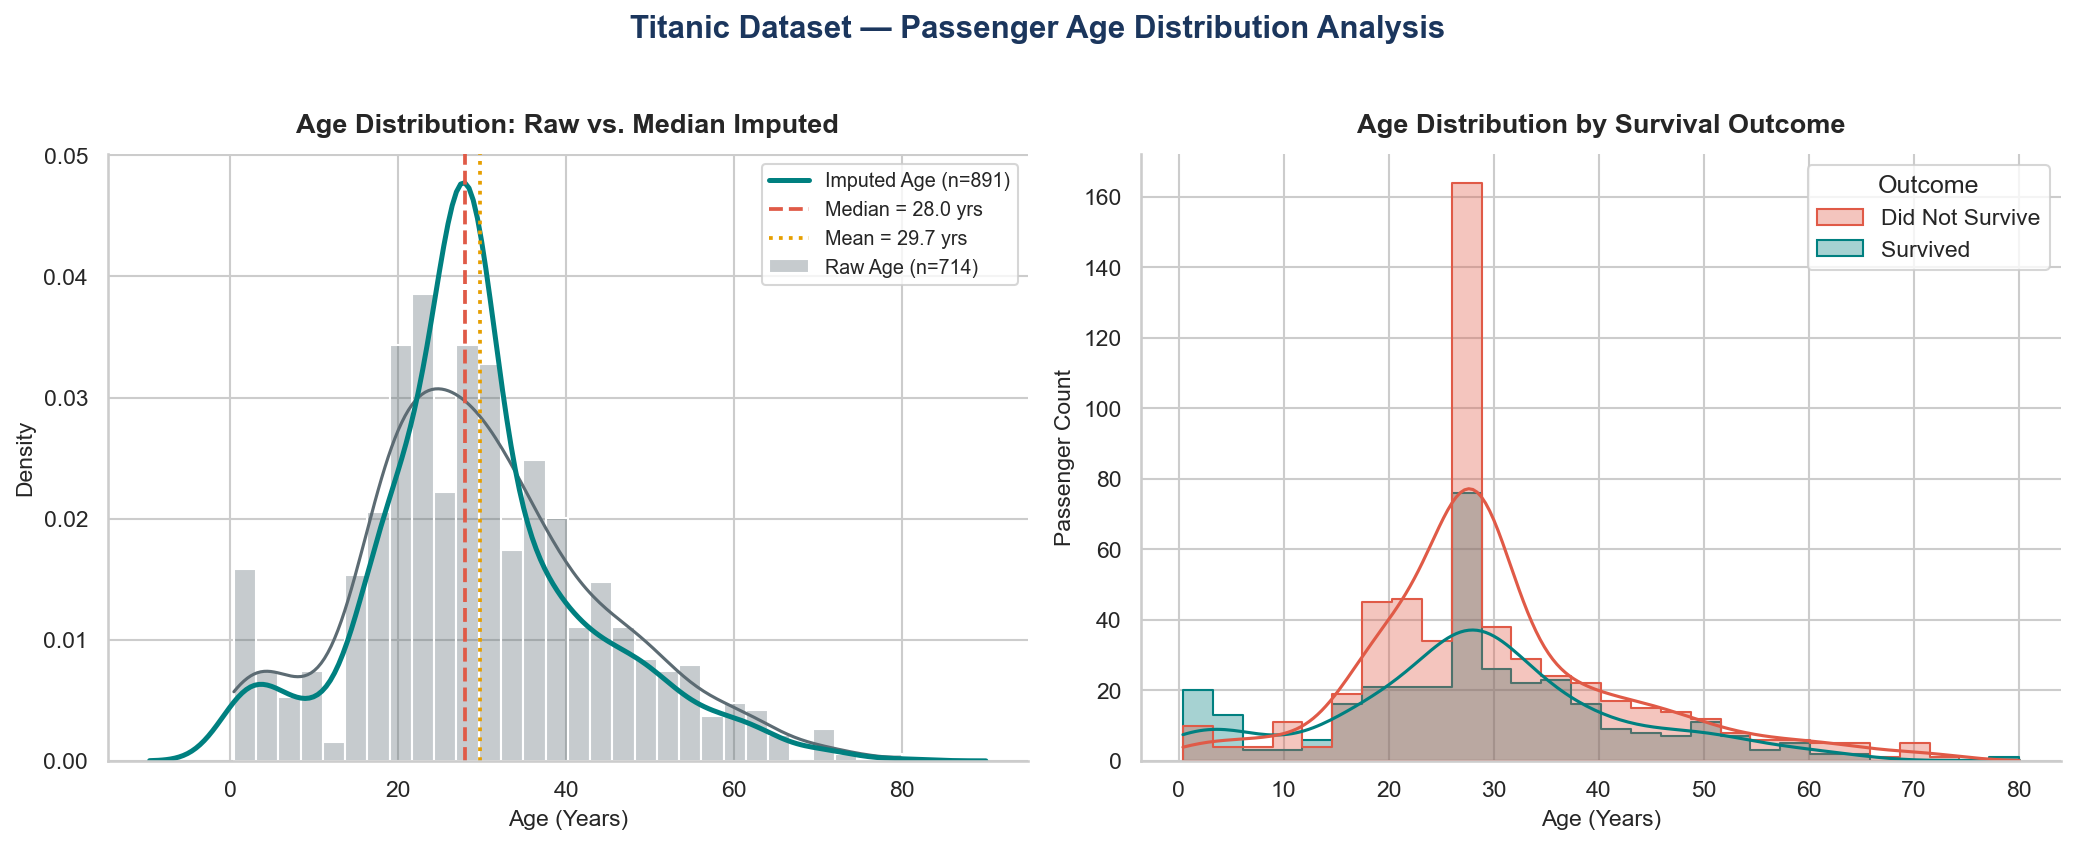

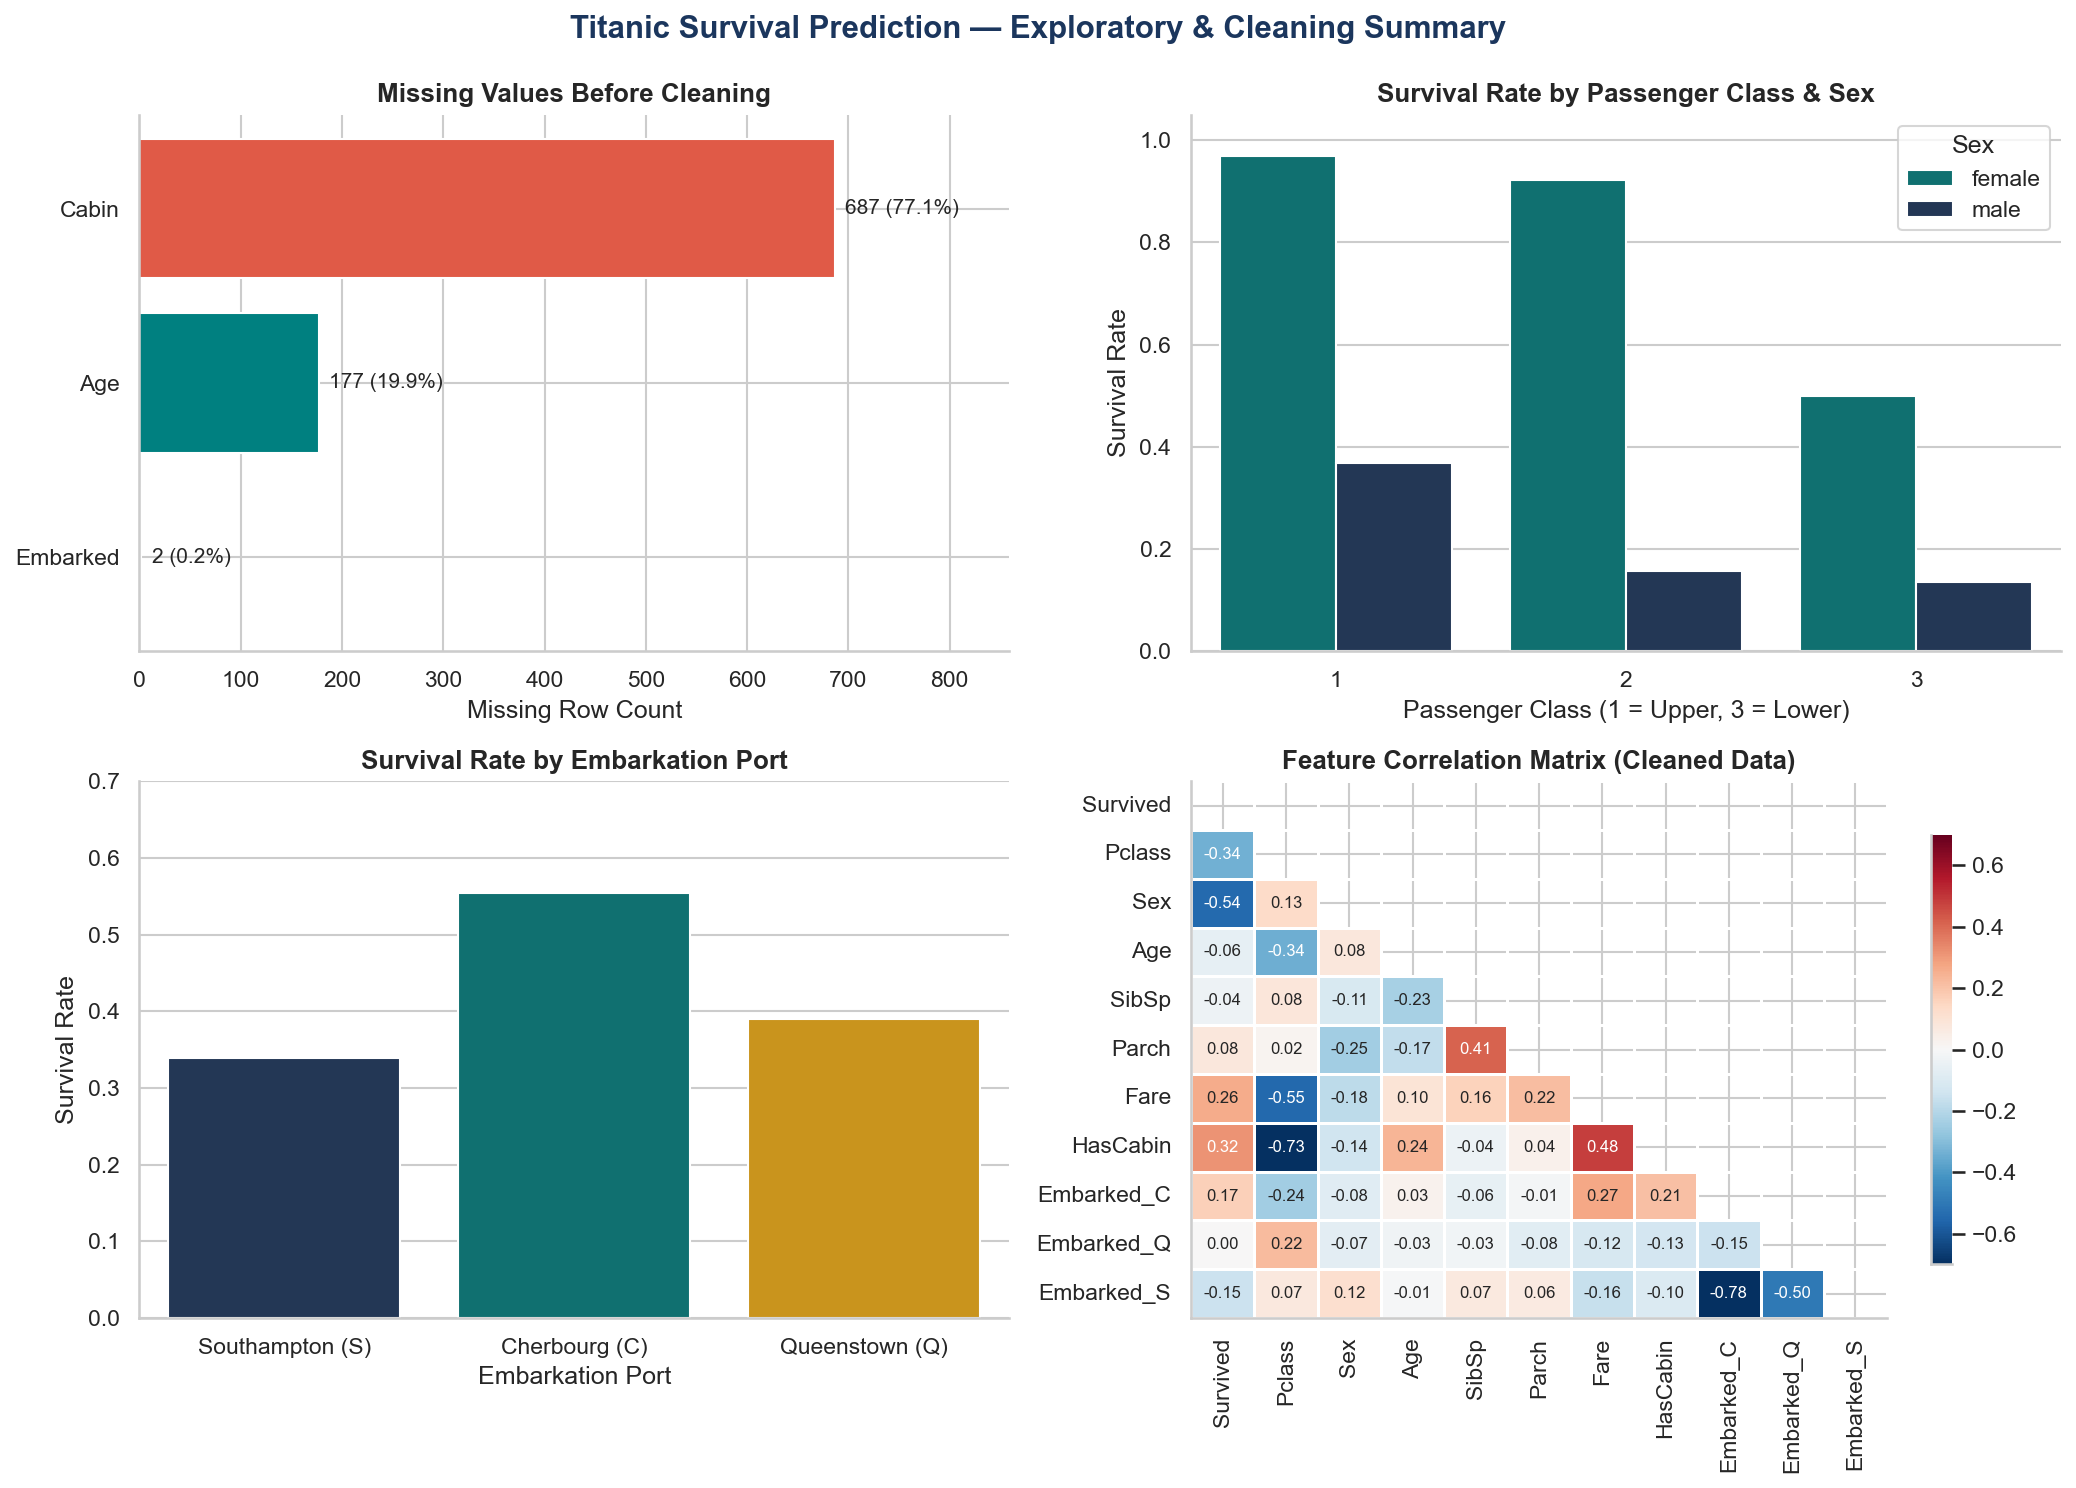

In [6]:
plot_age_distribution(df_raw, df_clean, meta)
plot_eda_summary(df_raw, df_clean)

from IPython.display import Image, display as ipy_display
ipy_display(Image(filename="outputs/age_distribution.png"))
ipy_display(Image(filename="outputs/titanic_eda_summary.png"))

## Task 4 & Survival Prediction: Export Cleaned CSV & Evaluate Baseline Models

In [7]:
CLEANED_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(CLEANED_CSV_PATH, index=False)
print(f"Saved cleaned dataset to {CLEANED_CSV_PATH} ({df_clean.shape[0]} rows, {df_clean.shape[1]} cols)")

results = evaluate_survival_models(df_raw)
for model_name, m in results.items():
    print(f"\n=== {model_name} ===")
    print(f"5-Fold CV Accuracy: {m['cv_accuracy_mean']:.4f} +/- {m['cv_accuracy_std']:.4f}")
    print(f"Holdout Accuracy  : {m['test_accuracy']:.4f} | ROC-AUC: {m['test_roc_auc']:.4f}")
    print(m["classification_report"])

Saved cleaned dataset to C:\Users\megha\MachineLearning\week1\outputs\titanic_cleaned.csv (891 rows, 12 cols)



=== Logistic Regression ===
5-Fold CV Accuracy: 0.7992 +/- 0.0277
Holdout Accuracy  : 0.8101 | ROC-AUC: 0.8402
                 precision    recall  f1-score   support

Did Not Survive       0.83      0.87      0.85       110
       Survived       0.78      0.71      0.74        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.80       179
   weighted avg       0.81      0.81      0.81       179


=== Random Forest ===
5-Fold CV Accuracy: 0.8244 +/- 0.0273
Holdout Accuracy  : 0.7989 | ROC-AUC: 0.8380
                 precision    recall  f1-score   support

Did Not Survive       0.80      0.89      0.84       110
       Survived       0.79      0.65      0.71        69

       accuracy                           0.80       179
      macro avg       0.80      0.77      0.78       179
   weighted avg       0.80      0.80      0.79       179

